In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import src.stability as stability

from importlib import reload
reload(stability)

from src.stability import (
    load_best_models,
    run_stability_analysis
)

## Importando os resultados

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuração visual
sns.set_theme(style="whitegrid", context="notebook")

# Caminhos
PATH_BEST = ROOT / "results" / "best_models2" / "best_models.csv"

PATH_STABILITY = (
    ROOT / "results" / "stability" / "stability_summary_consolidado2.csv"
)

best = pd.read_csv(PATH_BEST)
stability = pd.read_csv(PATH_STABILITY)

print("Best models:")
display(best.head())

print("\nStability summary:")
display(stability.head())

print("\nColunas de best_models:")
print(best.columns.tolist())

print("\nColunas de stability_summary:")
print(stability.columns.tolist())

Best models:


,Reduction,Clustering,Reduction_n_neighbors,Reduction_MN_ratio,Reduction_FP_ratio,Clustering_min_cluster_size,Clustering_min_samples,N_Clusters,N_Noise,Trustworthiness,Silhouette,ARI,NMI,Clustering_n_neighbors,Clustering_resolution,Reduction_min_dist,Cenario
0,PaCMAP,HDBSCAN,50,0.5,2.0,15.0,15.0,2,0,0.904420,0.839749,0.335787,0.487499,NaN,NaN,NaN,MAD 3.000
1,PaCMAP,Leiden,50,0.5,2.0,NaN,NaN,2,0,0.904420,0.839749,0.335787,0.487499,30.0,0.05,NaN,MAD 3.000
2,UMAP,HDBSCAN,15,NaN,NaN,75.0,20.0,2,0,0.916796,0.832842,0.332742,0.482116,NaN,NaN,0.01,MAD 3.000
3,UMAP,Leiden,15,NaN,NaN,NaN,NaN,2,0,0.916796,0.832842,0.332742,0.482116,30.0,0.05,0.01,MAD 3.000
4,PaCMAP,HDBSCAN,50,0.5,2.0,15.0,10.0,2,0,0.900325,0.831373,0.335787,0.487499,NaN,NaN,NaN,MAD 5.000



Stability summary:


,Model_ID,Cenario,Reduction,Clustering,N_Runs,Trustworthiness_media,Trustworthiness_std,Silhouette_media,Silhouette_std,ARI_media,ARI_std,NMI_media,NMI_std,N_Clusters_media,N_Clusters_std,N_Noise_media,N_Noise_std,ARI_estabilidade_media,ARI_estabilidade_std
0,MAD 3.000_PaCMAP_HDBSCAN,MAD 3.000,PaCMAP,HDBSCAN,10,0.903458,0.001574,0.836633,0.001594,0.334482,0.001537,0.483297,0.002735,2.0,0.000000,0.0,0.0,0.994876,0.003458
1,MAD 3.000_PaCMAP_Leiden,MAD 3.000,PaCMAP,Leiden,10,0.903458,0.001574,0.836633,0.001594,0.334482,0.001537,0.483297,0.002735,2.0,0.000000,0.0,0.0,0.994876,0.003458
2,MAD 3.000_UMAP_HDBSCAN,MAD 3.000,UMAP,HDBSCAN,10,0.919470,0.002369,0.819645,0.028828,0.331807,0.001971,0.481315,0.001690,2.0,0.000000,0.0,0.0,0.996419,0.004876
3,MAD 3.000_UMAP_Leiden,MAD 3.000,UMAP,Leiden,10,0.919470,0.002369,0.792906,0.102587,0.345741,0.044432,0.490732,0.030109,2.1,0.316228,0.0,0.0,0.948729,0.095898
4,MAD 5.000_PaCMAP_HDBSCAN,MAD 5.000,PaCMAP,HDBSCAN,10,0.896948,0.001582,0.828025,0.001110,0.337413,0.001282,0.487357,0.001747,2.0,0.000000,0.0,0.0,0.997222,0.002930



Colunas de best_models:
['Reduction', 'Clustering', 'Reduction_n_neighbors', 'Reduction_MN_ratio', 'Reduction_FP_ratio', 'Clustering_min_cluster_size', 'Clustering_min_samples', 'N_Clusters', 'N_Noise', 'Trustworthiness', 'Silhouette', 'ARI', 'NMI', 'Clustering_n_neighbors', 'Clustering_resolution', 'Reduction_min_dist', 'Cenario']

Colunas de stability_summary:
['Model_ID', 'Cenario', 'Reduction', 'Clustering', 'N_Runs', 'Trustworthiness_media', 'Trustworthiness_std', 'Silhouette_media', 'Silhouette_std', 'ARI_media', 'ARI_std', 'NMI_media', 'NMI_std', 'N_Clusters_media', 'N_Clusters_std', 'N_Noise_media', 'N_Noise_std', 'ARI_estabilidade_media', 'ARI_estabilidade_std']


In [3]:
def extrair_mad(df):
    df = df.copy()

    if "Cenario" not in df.columns:
        raise ValueError("A coluna 'Cenario' não foi encontrada.")

    df["MAD"] = (
        df["Cenario"]
        .astype(str)
        .str.extract(r"(\d+)", expand=False)
        .astype(float)
    )

    return df


best = extrair_mad(best)
stability = extrair_mad(stability)

# Padronização das chaves de comparação
for df in [best, stability]:
    for col in ["Cenario", "Reduction", "Clustering"]:
        if col not in df.columns:
            raise ValueError(f"Coluna ausente: {col}")

        df[col] = df[col].astype(str).str.strip()

print("Cenários encontrados:", sorted(best["MAD"].dropna().unique()))

Cenários encontrados: [np.float64(3.0), np.float64(5.0), np.float64(10.0), np.float64(20.0)]


## Análise das métricas do Grid Search

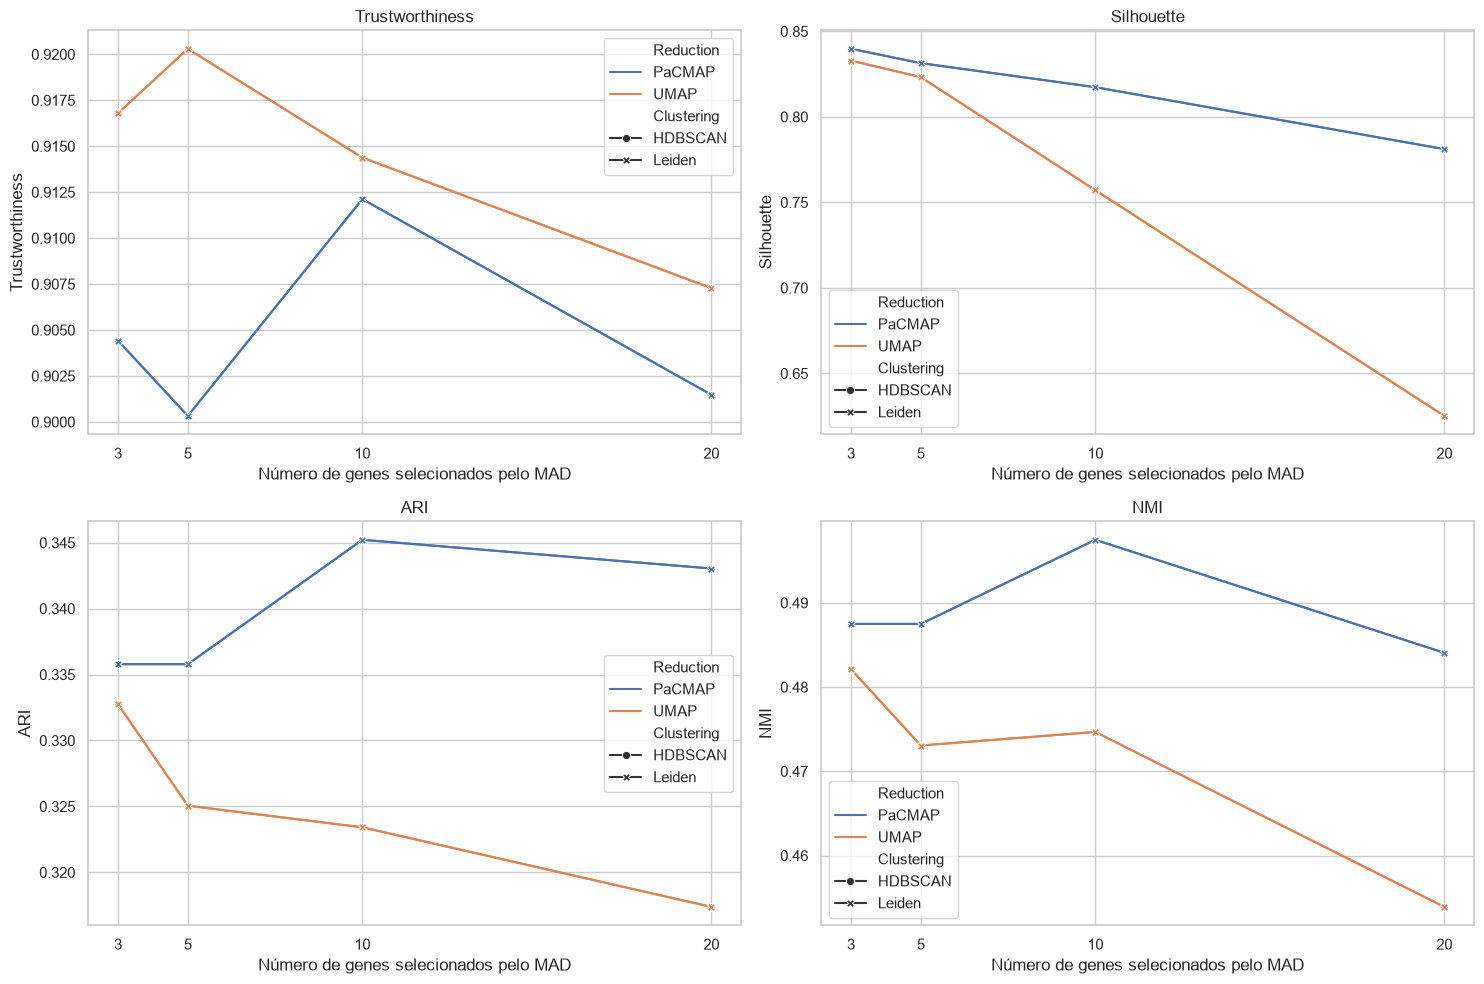

In [4]:
metricas_grid = [
    "Trustworthiness",
    "Silhouette",
    "ARI",
    "NMI"
]

# Evita duplicação visual caso HDBSCAN e Leiden tenham
# métricas idênticas para determinada combinação.
best_plot = best.drop_duplicates(
    subset=["Cenario", "Reduction", "Clustering", *metricas_grid]
)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, metrica in zip(axes.flat, metricas_grid):

    sns.lineplot(
        data=best_plot,
        x="MAD",
        y=metrica,
        hue="Reduction",
        style="Clustering",
        markers=True,
        dashes=False,
        errorbar=None,
        ax=ax
    )

    ax.set_title(metrica)
    ax.set_xlabel("Número de genes selecionados pelo MAD")
    ax.set_ylabel(metrica)
    ax.set_xticks(sorted(best_plot["MAD"].dropna().unique()))

plt.tight_layout()
plt.show()

## Análise das métricas de estabilidade

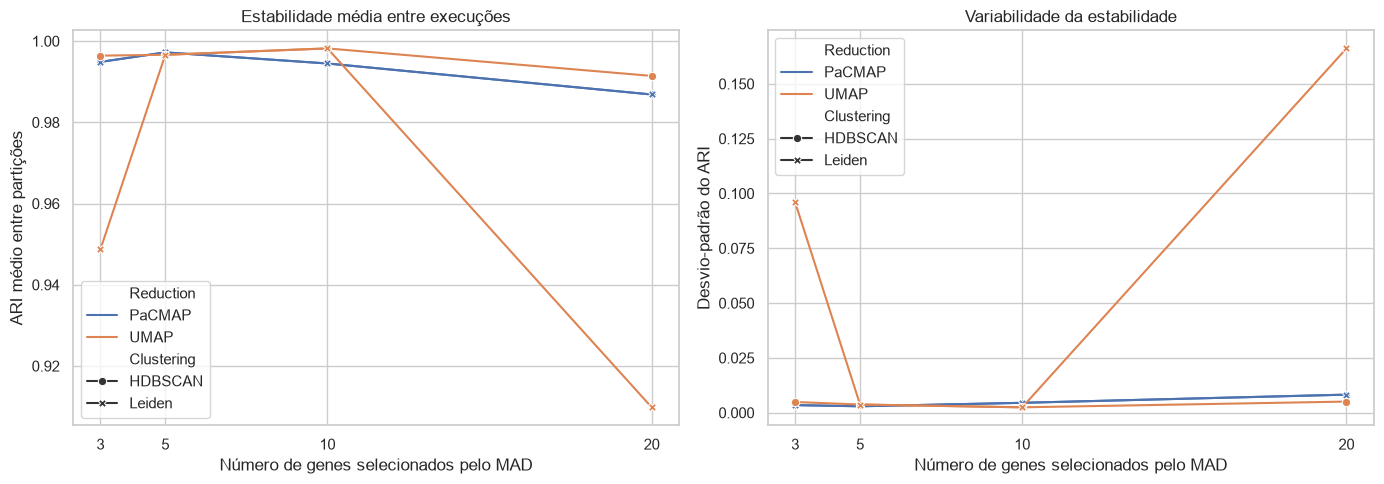

In [5]:
# Verificação das colunas de estabilidade
colunas_estabilidade = [
    "ARI_estabilidade_media",
    "ARI_estabilidade_std"
]

for col in colunas_estabilidade:
    if col not in stability.columns:
        raise ValueError(
            f"Coluna '{col}' não encontrada. "
            f"Colunas disponíveis: {stability.columns.tolist()}"
        )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(
    data=stability,
    x="MAD",
    y="ARI_estabilidade_media",
    hue="Reduction",
    style="Clustering",
    markers=True,
    dashes=False,
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Estabilidade média entre execuções")
axes[0].set_xlabel("Número de genes selecionados pelo MAD")
axes[0].set_ylabel("ARI médio entre partições")

sns.lineplot(
    data=stability,
    x="MAD",
    y="ARI_estabilidade_std",
    hue="Reduction",
    style="Clustering",
    markers=True,
    dashes=False,
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Variabilidade da estabilidade")
axes[1].set_xlabel("Número de genes selecionados pelo MAD")
axes[1].set_ylabel("Desvio-padrão do ARI")

for ax in axes:
    ax.set_xticks(sorted(stability["MAD"].dropna().unique()))

plt.tight_layout()
plt.show()

## Relação de desempenho e estabilidade

In [6]:
chaves = ["Cenario", "Reduction", "Clustering"]

# Verificar se existem combinações repetidas
print("Duplicatas em best_models:")
display(
    best[best.duplicated(subset=chaves, keep=False)]
)

print("Duplicatas em stability_summary:")
display(
    stability[stability.duplicated(subset=chaves, keep=False)]
)

# Selecionar as variáveis necessárias
best_merge = best[
    chaves + [
        "MAD",
        "Trustworthiness",
        "Silhouette",
        "ARI",
        "NMI"
    ]
].copy()

stability_merge = stability[
    chaves + [
        "ARI_estabilidade_media",
        "ARI_estabilidade_std",
        "N_Runs"
    ]
].copy()

# Cruzamento
consolidado = pd.merge(
    best_merge,
    stability_merge,
    on=chaves,
    how="outer",
    suffixes=("_grid", "_stability"),
    indicator=True
)

print("Resultado do cruzamento:")
display(consolidado)

print("\nCorrespondência entre os arquivos:")
print(consolidado["_merge"].value_counts())

Duplicatas em best_models:


,Reduction,Clustering,Reduction_n_neighbors,Reduction_MN_ratio,Reduction_FP_ratio,Clustering_min_cluster_size,Clustering_min_samples,N_Clusters,N_Noise,Trustworthiness,Silhouette,ARI,NMI,Clustering_n_neighbors,Clustering_resolution,Reduction_min_dist,Cenario,MAD


Duplicatas em stability_summary:


,Model_ID,Cenario,Reduction,Clustering,N_Runs,Trustworthiness_media,Trustworthiness_std,Silhouette_media,Silhouette_std,ARI_media,ARI_std,NMI_media,NMI_std,N_Clusters_media,N_Clusters_std,N_Noise_media,N_Noise_std,ARI_estabilidade_media,ARI_estabilidade_std,MAD


Resultado do cruzamento:


,Cenario,Reduction,Clustering,MAD,Trustworthiness,Silhouette,ARI,NMI,ARI_estabilidade_media,ARI_estabilidade_std,N_Runs,_merge
0,MAD 10.000,PaCMAP,HDBSCAN,10.0,0.912121,0.817311,0.345221,0.497479,0.994486,0.004508,10,both
1,MAD 10.000,PaCMAP,Leiden,10.0,0.912121,0.817311,0.345221,0.497479,0.994486,0.004508,10,both
2,MAD 10.000,UMAP,HDBSCAN,10.0,0.914378,0.757114,0.323415,0.474673,0.998200,0.002451,10,both
3,MAD 10.000,UMAP,Leiden,10.0,0.914378,0.757114,0.323415,0.474673,0.998200,0.002451,10,both
4,MAD 20.000,PaCMAP,HDBSCAN,20.0,0.901477,0.781121,0.343044,0.484064,0.986851,0.008236,10,both
5,MAD 20.000,PaCMAP,Leiden,20.0,0.901477,0.781121,0.343044,0.484064,0.986851,0.008236,10,both
6,MAD 20.000,UMAP,HDBSCAN,20.0,0.907278,0.625152,0.317374,0.453904,0.991428,0.005071,10,both
7,MAD 20.000,UMAP,Leiden,20.0,0.907278,0.625152,0.317374,0.453904,0.909820,0.166150,10,both
8,MAD 3.000,PaCMAP,HDBSCAN,3.0,0.904420,0.839749,0.335787,0.487499,0.994876,0.003458,10,both
9,MAD 3.000,PaCMAP,Leiden,3.0,0.904420,0.839749,0.335787,0.487499,0.994876,0.003458,10,both



Correspondência entre os arquivos:
_merge
both          16
left_only      0
right_only     0
Name: count, dtype: int64


## ARI

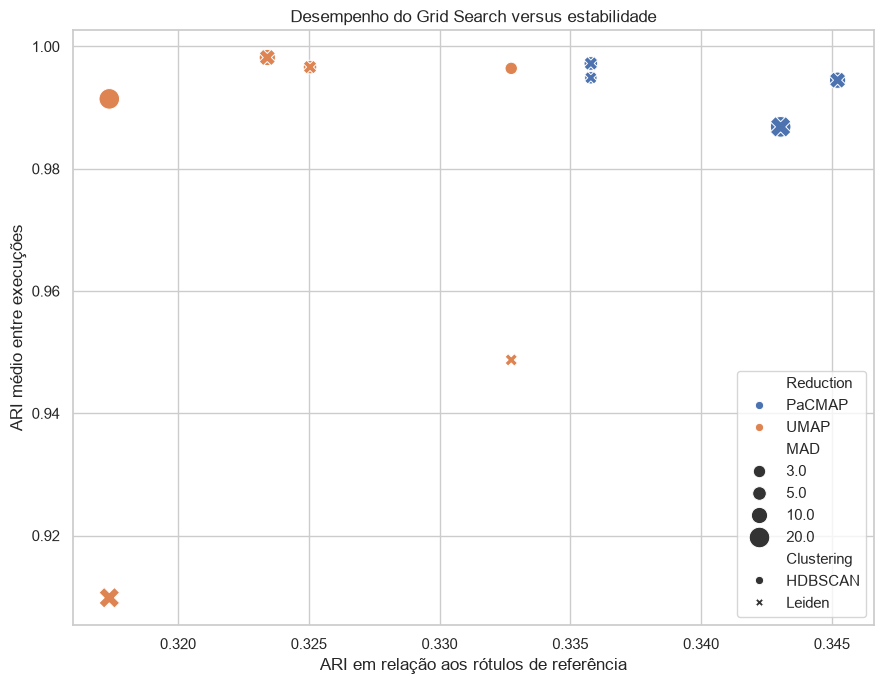

In [7]:
dados_completos = consolidado.dropna(
    subset=["ARI", "ARI_estabilidade_media"]
).copy()

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=dados_completos,
    x="ARI",
    y="ARI_estabilidade_media",
    hue="Reduction",
    style="Clustering",
    size="MAD",
    sizes=(80, 220)
)

plt.title("Desempenho do Grid Search versus estabilidade")
plt.xlabel("ARI em relação aos rótulos de referência")
plt.ylabel("ARI médio entre execuções")

plt.tight_layout()
plt.show()

In [8]:
colunas_tabela = [
    "MAD",
    "Reduction",
    "Clustering",
    "Trustworthiness",
    "Silhouette",
    "ARI",
    "NMI",
    "ARI_estabilidade_media",
    "ARI_estabilidade_std",
    "N_Runs"
]

tabela_final = (
    dados_completos[colunas_tabela]
    .sort_values(
        by=["MAD", "Reduction", "Clustering"]
    )
    .reset_index(drop=True)
)

display(
    tabela_final.style.format({
        "Trustworthiness": "{:.4f}",
        "Silhouette": "{:.4f}",
        "ARI": "{:.4f}",
        "NMI": "{:.4f}",
        "ARI_estabilidade_media": "{:.4f}",
        "ARI_estabilidade_std": "{:.4f}"
    })
)

,MAD,Reduction,Clustering,Trustworthiness,Silhouette,ARI,NMI,ARI_estabilidade_media,ARI_estabilidade_std,N_Runs
0,3.000000,PaCMAP,HDBSCAN,0.9044,0.8397,0.3358,0.4875,0.9949,0.0035,10
1,3.000000,PaCMAP,Leiden,0.9044,0.8397,0.3358,0.4875,0.9949,0.0035,10
2,3.000000,UMAP,HDBSCAN,0.9168,0.8328,0.3327,0.4821,0.9964,0.0049,10
3,3.000000,UMAP,Leiden,0.9168,0.8328,0.3327,0.4821,0.9487,0.0959,10
4,5.000000,PaCMAP,HDBSCAN,0.9003,0.8314,0.3358,0.4875,0.9972,0.0029,10
5,5.000000,PaCMAP,Leiden,0.9003,0.8314,0.3358,0.4875,0.9972,0.0029,10
6,5.000000,UMAP,HDBSCAN,0.9203,0.8232,0.3250,0.4731,0.9966,0.0037,10
7,5.000000,UMAP,Leiden,0.9203,0.8232,0.3250,0.4731,0.9966,0.0037,10
8,10.000000,PaCMAP,HDBSCAN,0.9121,0.8173,0.3452,0.4975,0.9945,0.0045,10
9,10.000000,PaCMAP,Leiden,0.9121,0.8173,0.3452,0.4975,0.9945,0.0045,10


In [9]:
metricas_para_maximizar = [
    "Trustworthiness",
    "Silhouette",
    "ARI",
    "NMI",
    "ARI_estabilidade_media"
]

for metrica in metricas_para_maximizar:

    melhor = dados_completos.loc[
        dados_completos[metrica].idxmax()
    ]

    print(f"\nMaior valor de {metrica}:")
    print(
        f"MAD: {melhor['MAD']:.0f} | "
        f"Redução: {melhor['Reduction']} | "
        f"Clustering: {melhor['Clustering']} | "
        f"Valor: {melhor[metrica]:.4f}"
    )


Maior valor de Trustworthiness:
MAD: 5 | Redução: UMAP | Clustering: HDBSCAN | Valor: 0.9203

Maior valor de Silhouette:
MAD: 3 | Redução: PaCMAP | Clustering: HDBSCAN | Valor: 0.8397

Maior valor de ARI:
MAD: 10 | Redução: PaCMAP | Clustering: HDBSCAN | Valor: 0.3452

Maior valor de NMI:
MAD: 10 | Redução: PaCMAP | Clustering: HDBSCAN | Valor: 0.4975

Maior valor de ARI_estabilidade_media:
MAD: 10 | Redução: UMAP | Clustering: HDBSCAN | Valor: 0.9982


In [10]:
consolidado.to_csv(
    "results/analise_consolidada2.csv",
    index=False
)

print("Tabela consolidada salva com sucesso.")

Tabela consolidada salva com sucesso.
